# Chapter 9: Fractions Are Places

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** see a fraction as a place on the number line, found by counting equal steps from zero. You will count quarter steps, watch seven fourths pass one, read a 2-meter ribbon with two different names, and see why 1/2 and 4/8 are the same place.

A note before we start: the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight through like a book.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from matplotlib.patches import Rectangle

TEAL, GOLD, TERRA, NAVY, INK, GREY, LIGHT = "#1f7a80", "#c9a227", "#c4552d", "#1f3a5f", "#222222", "#777777", "#dddddd"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def frac(x):
    """Write a Fraction the plain way: 3/4, or 2 for a whole number."""
    x = Fraction(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def mixed(x):
    """Write a Fraction as a mixed number: 11/4 becomes 2 3/4."""
    x = Fraction(x)
    whole, rem = divmod(x.numerator, x.denominator)
    if rem == 0:
        return str(whole)
    if whole == 0:
        return f"{rem}/{x.denominator}"
    return f"{whole} {rem}/{x.denominator}"

def bare(ax):
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)

## 1. Count steps, land on a place

**Question in plain words:** Where does a fraction live on the number line, and how do you find it without a formula?

$$a/b \qquad\qquad 1/4 + 1/4 + 1/4 = 3/4$$

**What the symbols mean:** In $a/b$, the bottom number $b$ (the denominator) says how many equal steps make one whole, so each step has size $1/b$. The top number $a$ (the numerator) counts how many of those steps you take from zero.

Here we take $a = 3$ steps of size $1/4$.

In [2]:
a, b = 3, 4                      # 3 steps, each one fourth of a whole
step = Fraction(1, b)
end = a * step
print(f"step size = 1/{b}")
print("steps: " + " + ".join([f"1/{b}"]*a) + f" = {a}/{b}")
print(f"location = {a} x 1/{b} = {a}/{b}")
print(f"check by division: {a} / {b} = {a/b}")
print(f"spaces counted: {a}, marks used (counting 0): {a+1}")

print()
print("Other menu values (steps, step size, location, decimal):")
for steps, den in [(3,4),(4,4),(6,4),(7,4),(3,8),(4,8),(6,8),(7,8)]:
    e = Fraction(steps, den)
    extra = f" = {mixed(e)}" if e.denominator != den else ""
    print(f"  {steps} steps of 1/{den}: {steps}/{den}{extra}, decimal {float(e):g}")

step size = 1/4
steps: 1/4 + 1/4 + 1/4 = 3/4
location = 3 x 1/4 = 3/4
check by division: 3 / 4 = 0.75
spaces counted: 3, marks used (counting 0): 4

Other menu values (steps, step size, location, decimal):
  3 steps of 1/4: 3/4, decimal 0.75
  4 steps of 1/4: 4/4 = 1, decimal 1
  6 steps of 1/4: 6/4 = 1 1/2, decimal 1.5
  7 steps of 1/4: 7/4, decimal 1.75
  3 steps of 1/8: 3/8, decimal 0.375
  4 steps of 1/8: 4/8 = 1/2, decimal 0.5
  6 steps of 1/8: 6/8 = 3/4, decimal 0.75
  7 steps of 1/8: 7/8, decimal 0.875


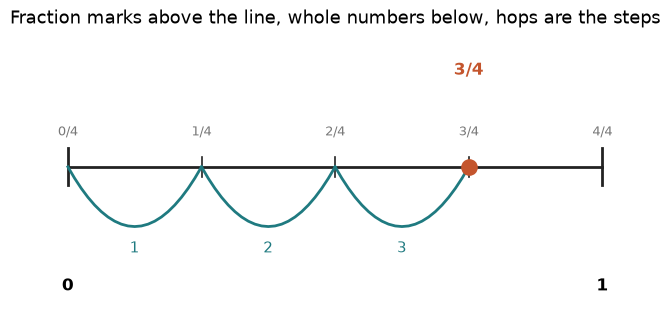

In [3]:
def location_picture(steps=3, b=4):
    end = Fraction(steps, b)
    top = 2 if steps > b else 1
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot([0, top], [0, 0], color=INK, lw=2)
    for k in range(top*b + 1):
        x = k / b
        major = k % b == 0
        ax.plot([x, x], [-0.13, 0.13] if major else [-0.07, 0.07], color=INK, lw=2 if major else 1.2)
        ax.text(x, 0.2 if not (b == 8 and k % 2) else 0.38, f"{k}/{b}", ha="center", va="bottom", fontsize=9, color=GREY)
    for k in range(steps):
        x0, x1 = k/b, (k+1)/b
        t = np.linspace(0, 1, 21)
        ax.plot(x0 + (x1-x0)*t, -0.42*4*t*(1-t), color=TEAL, lw=2)
        ax.text((x0+x1)/2, -0.52, str(k+1), ha="center", va="top", color=TEAL)
    ax.plot([float(end)], [0], "o", color=TERRA, ms=11, zorder=5)
    label = f"{steps}/{b}" + (f" = {frac(end)}" if end.denominator != b else "")
    ax.text(float(end), 0.62, label, ha="center", va="bottom", fontsize=12, color=TERRA, fontweight="bold")
    for w in range(top+1):
        ax.text(w, -0.78, str(w), ha="center", va="top", fontsize=12, fontweight="bold")
    ax.set_xlim(-0.08, top+0.08); ax.set_ylim(-1.0, 0.95); ax.set_xticks([])
    ax.spines["bottom"].set_visible(False); bare(ax)
    ax.set_title("Fraction marks above the line, whole numbers below, hops are the steps")
    plt.show()

location_picture(3, 4)

**What this shows:** Each curved hop is one step of size $1/4$. The dot is where the count of hops stops. The numbers above the line are the marks, and the hops are the spaces between them, so you count spaces, not marks.

**Where it stops working:** The whole from 0 to 1 has to be split into equal steps. If the steps are unequal, counting them no longer gives a fraction of the whole.

## 2. Seven fourths passes one

**Question in plain words:** What happens when the count of fourths is bigger than 4?

$$4/4 = 1 \qquad\qquad \frac{11}{4}=\frac84+\frac34=2\frac34$$

**What the symbols mean:** $11/4$ means eleven copies of $1/4$, and $7/4$ means seven. $4/4$ is one whole. The mixed number $2\frac34$ means $2 + \frac34$: the space stands for plus, not times.

We start with $7/4$.

In [4]:
n = 7
wholes, rem = divmod(n, 4)
print(f"{n} = {wholes} x 4 + {rem}, so {wholes} complete whole")
print(f"{n}/4 = " + " + ".join(["4/4"]*wholes + [f"{rem}/4"]) + f" = {wholes} {rem}/4")
print(f"reverse: {wholes} x 4 + {rem} = {wholes*4 + rem} fourths")

print()
print("Other menu values:")
for m in [4, 7, 8, 11]:
    w, r = divmod(m, 4)
    name = str(w) if r == 0 else f"{w} {r}/4"
    print(f"  {m}/4: {m} = {w} x 4 + {r}  ->  {name}   (back: {w} x 4 + {r} = {w*4+r})")

7 = 1 x 4 + 3, so 1 complete whole
7/4 = 4/4 + 3/4 = 1 3/4
reverse: 1 x 4 + 3 = 7 fourths

Other menu values:
  4/4: 4 = 1 x 4 + 0  ->  1   (back: 1 x 4 + 0 = 4)
  7/4: 7 = 1 x 4 + 3  ->  1 3/4   (back: 1 x 4 + 3 = 7)
  8/4: 8 = 2 x 4 + 0  ->  2   (back: 2 x 4 + 0 = 8)
  11/4: 11 = 2 x 4 + 3  ->  2 3/4   (back: 2 x 4 + 3 = 11)


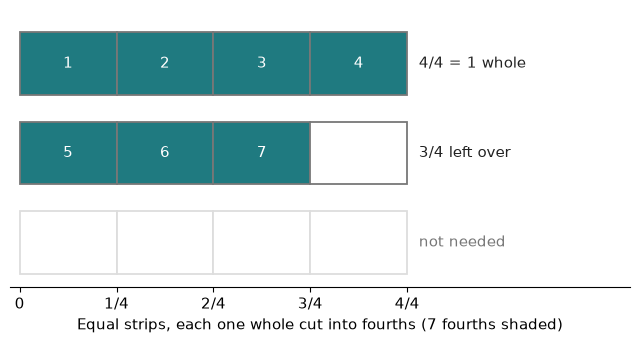

In [5]:
def passes_one(n=7):
    wholes, rem = divmod(n, 4)
    strips = wholes + (1 if rem else 0)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for s in range(3):
        y = 2 - s
        for c in range(4):
            k = s*4 + c
            filled = k < n
            ax.add_patch(Rectangle((c, y+0.1), 1, 0.7, facecolor=TEAL if filled else "white",
                                   edgecolor=GREY if s < strips else LIGHT, lw=1.3))
            if filled:
                ax.text(c+0.5, y+0.45, str(k+1), ha="center", va="center", color="white")
        if s < wholes: label = "4/4 = 1 whole"
        elif s == wholes and rem: label = f"{rem}/4 left over"
        else: label = "not needed"
        ax.text(4.12, y+0.45, label, va="center", color=INK if s < strips else GREY)
    ax.set_xlim(-0.1, 6.3); ax.set_ylim(-0.05, 3.05)
    ax.set_xticks([0,1,2,3,4]); ax.set_xticklabels(["0","1/4","2/4","3/4","4/4"])
    ax.set_xlabel(f"Equal strips, each one whole cut into fourths ({n} fourths shaded)")
    bare(ax); plt.show()

passes_one(7)

**What this shows:** Shade fourths in order. Every time four are shaded, one strip is a complete whole. What is shaded in the next strip is the fractional part of the mixed number: $7/4 = 1\frac34$.

**Where it stops working:** All strips must be the same length, so every $4/4$ is the same whole. If the strips differed in length, two of them would not add to 2.

## 3. One ribbon, two correct names

**Question in plain words:** How can the same piece be one fourth and one half at once?

$$2\div4=\frac12$$

**What the symbols mean:** The whole ribbon is one whole on the top line. One meter is one whole on the bottom line. $2 \div 4$ is the length of one piece in meters. The ribbon is 2 meters long, cut into 4 equal pieces, and we shade 3 pieces.

In [6]:
length, pieces = 2, 3
part = Fraction(length, 4)
share = Fraction(pieces, 4)
meters = pieces * part
rest_pieces = 4 - pieces
rest = rest_pieces * part
print(f"length of one piece = {length} / 4 = {frac(part)} meter")
print(f"fraction of the ribbon = {pieces}/4")
print(f"length in meters = {pieces} x {frac(part)} = {pieces*part.numerator}/{part.denominator} = {mixed(meters)} meters")
print(f"pieces not shaded = {rest_pieces} ({mixed(rest)} m)")
print(f"check: {mixed(meters)} + {mixed(rest)} = {length} meters")

print()
print("Same walk for the 3-meter ribbon with 2 pieces shaded:")
l, p = 3, 2
pt = Fraction(l, 4)
print(f"  one piece = {l} / 4 = {frac(pt)} meter; {p} pieces = {p} x {frac(pt)} = {mixed(p*pt)} meters, which is {p}/4 = {frac(Fraction(p,4))} of the ribbon")

length of one piece = 2 / 4 = 1/2 meter
fraction of the ribbon = 3/4
length in meters = 3 x 1/2 = 3/2 = 1 1/2 meters
pieces not shaded = 1 (1/2 m)
check: 1 1/2 + 1/2 = 2 meters

Same walk for the 3-meter ribbon with 2 pieces shaded:
  one piece = 3 / 4 = 3/4 meter; 2 pieces = 2 x 3/4 = 1 1/2 meters, which is 2/4 = 1/2 of the ribbon


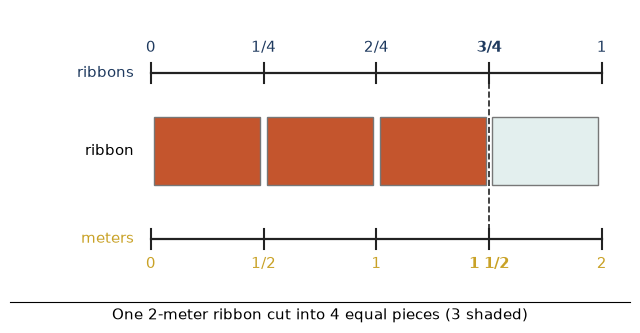

In [7]:
def ribbon(pieces=3, length=2):
    part = Fraction(length, 4)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot([0,4],[1.6,1.6], color=INK, lw=1.6); ax.plot([0,4],[-0.1,-0.1], color=INK, lw=1.6)
    for k in range(5):
        ax.plot([k,k],[1.5,1.7], color=INK); ax.plot([k,k],[-0.2,0.0], color=INK)
        ax.text(k, 1.78, (f"{k}/4" if 0 < k < 4 else str(k//4)), ha="center", va="bottom", color=NAVY,
                fontweight="bold" if k == pieces else "normal")
        ax.text(k, -0.28, mixed(k*part), ha="center", va="top", color=GOLD,
                fontweight="bold" if k == pieces else "normal")
    for k in range(4):
        ax.add_patch(Rectangle((k+0.03, 0.45), 0.94, 0.7, facecolor=TERRA if k < pieces else "#e3efee",
                               edgecolor=GREY))
    ax.plot([pieces]*2, [-0.1, 1.6], color=INK, ls="dashed", lw=1.2)
    ax.text(-0.15, 1.6, "ribbons", ha="right", va="center", color=NAVY)
    ax.text(-0.15, 0.8, "ribbon", ha="right", va="center")
    ax.text(-0.15, -0.1, "meters", ha="right", va="center", color=GOLD)
    ax.set_xlim(-1.25, 4.25); ax.set_ylim(-0.75, 2.25); ax.set_xticks([])
    ax.set_xlabel(f"One {length}-meter ribbon cut into 4 equal pieces ({pieces} shaded)")
    bare(ax); plt.show()

ribbon(3, 2)

**What this shows:** The ribbon sits between two number lines. The top counts ribbons, the bottom counts meters. The dashed line marks one physical spot that gets a name on each line: $3/4$ of the ribbon, or $1\frac12$ meters. Same endpoint, two correct names, because the wholes differ.

**Where it stops working:** The four pieces must be equal, and the ribbon's length here is a stated value, not a measurement of anything real. Without a unit, "one half" cannot be checked, so write the unit beside the fraction.

## 4. One place, more than one name

**Question in plain words:** Why is $4/8$ the same place as $1/2$ when both numbers changed?

$$a/b = (a \times n)/(b \times n) \qquad\qquad 1/2 = (1 \times 4)/(2 \times 4) = 4/8$$

**What the symbols mean:** $a/b$ is the starting fraction. $n$ is a positive whole number: every old part is cut into $n$ equal smaller parts. We start from $1/2$ and use $n = 4$.

In [8]:
a, b, n = 1, 2, 4
na, nb = a*n, b*n
print(f"new name = ({a} x {n})/({b} x {n}) = {na}/{nb}")
print(f"part size: 1/{b} becomes 1/{nb}")
print(f"decimals: {a} / {b} = {a/b:.2f} and {na} / {nb} = {na/nb:.2f}")
print(f"reverse: ({na} / {n})/({nb} / {n}) = {na//n}/{nb//n}")

print()
print("Other menu values:")
for (aa, bb) in [(1,2),(3,4)]:
    for nn in [1,2,3,4]:
        print(f"  {aa}/{bb} with n = {nn}: ({aa} x {nn})/({bb} x {nn}) = {aa*nn}/{bb*nn}, decimal {aa*nn/(bb*nn):.2f}")

new name = (1 x 4)/(2 x 4) = 4/8
part size: 1/2 becomes 1/8
decimals: 1 / 2 = 0.50 and 4 / 8 = 0.50
reverse: (4 / 4)/(8 / 4) = 1/2

Other menu values:
  1/2 with n = 1: (1 x 1)/(2 x 1) = 1/2, decimal 0.50
  1/2 with n = 2: (1 x 2)/(2 x 2) = 2/4, decimal 0.50
  1/2 with n = 3: (1 x 3)/(2 x 3) = 3/6, decimal 0.50
  1/2 with n = 4: (1 x 4)/(2 x 4) = 4/8, decimal 0.50
  3/4 with n = 1: (3 x 1)/(4 x 1) = 3/4, decimal 0.75
  3/4 with n = 2: (3 x 2)/(4 x 2) = 6/8, decimal 0.75
  3/4 with n = 3: (3 x 3)/(4 x 3) = 9/12, decimal 0.75
  3/4 with n = 4: (3 x 4)/(4 x 4) = 12/16, decimal 0.75


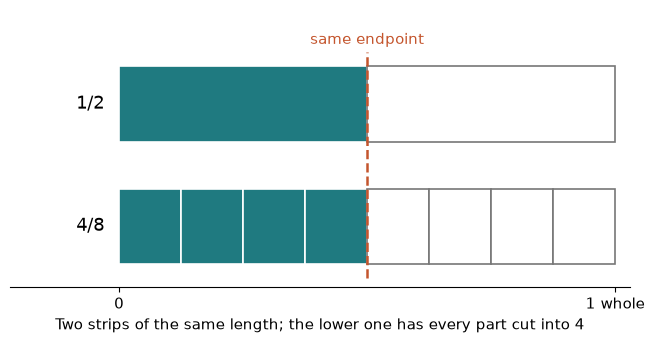

In [9]:
def rename(a=1, b=2, n=4):
    na, nb = a*n, b*n
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for count, parts, y in [(a, b, 1.3), (na, nb, 0.0)]:
        for k in range(parts):
            ax.add_patch(Rectangle((k/parts, y), 1/parts, 0.8, facecolor=TEAL if k < count else "white",
                                   edgecolor="white" if k < count else GREY, lw=1.2))
        ax.text(-0.03, y+0.4, f"{count}/{parts}", ha="right", va="center", fontsize=13)
    ax.plot([a/b]*2, [-0.15, 2.25], color=TERRA, ls="dashed", lw=1.8)
    ax.text(a/b, 2.3, "same endpoint", ha="center", va="bottom", color=TERRA)
    ax.set_xlim(-0.22, 1.03); ax.set_ylim(-0.25, 2.7)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["0", "1 whole"])
    ax.set_xlabel(f"Two strips of the same length; the lower one has every part cut into {n}")
    bare(ax); plt.show()

rename(1, 2, 4)

**What this shows:** Both strips are the same whole. Cutting every part into $n$ multiplies the count of parts and the count of shaded parts by $n$, so the shaded length stays put. Nothing was added or removed.

**Where it stops working:** You need the same whole and the same factor on top and bottom. Adding the same number to top and bottom is not renaming: $2/3$ and $4/5$ are different places.

## Practice

**1.** On a line marked in sixths, where do 5 steps from zero end, and how many marks have you passed, counting 0?

<details><summary>Show answer</summary>

Each step is $1/6$, so 5 steps: $5 \times 1/6 = 5/6$, one step short of 1. Five spaces use $5 + 1 = 6$ marks: $0/6$ through $5/6$.
</details>

**2.** Write $9/4$ as a mixed number and check it by turning it back into fourths.

<details><summary>Show answer</summary>

$9 = 2 \times 4 + 1$, so $9/4 = 4/4 + 4/4 + 1/4 = 2\frac14$. Back again: $2 \times 4 + 1 = 9$ fourths.
</details>

**3.** A 3-meter ribbon is cut into 4 equal pieces. How long are 2 pieces, and what fraction of the ribbon are they?

<details><summary>Show answer</summary>

One piece is $3 \div 4 = 3/4$ meter. Two pieces are $2 \times 3/4 = 6/4 = 1\frac12$ meters, which is $2/4 = 1/2$ of the ribbon.
</details>

**4.** What factor $n$ turns $2/3$ into $6/9$, and does the place move?

<details><summary>Show answer</summary>

$n = 3$, because $(2 \times 3)/(3 \times 3) = 6/9$. The place does not move: both name the same point.
</details>